# Problem
## Single-fiber diffusivity from measured thermal waves
Recover axial diffusivity from two QF01 infrared lock-in acquisitions. All plotted fresh methods below execute local mathematics on the complete supplied observations. Original results are method references, **not measured ground truth**. The original paper investigates frequency, power, lens and material effects; only the two available frequency images are bound here. We preserve its relevant amplitude-versus-phase and slope-product comparison, without inventing missing sweeps.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,FREQUENCIES,PIXEL_MM
from src.solvers import reconstruct
from src.visualization import profile_figure,relative_error
spec=importlib.util.spec_from_file_location('thermal_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
amplitude,phase=load_data(ROOT/'data/raw_data.npz')
upstream=dict(np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False))
print('Native shapes:',amplitude.shape,phase.shape,'frequencies:',FREQUENCIES,'pixel mm:',PIXEL_MM)

Native shapes: (2, 164, 1280) (2, 164, 1280) frequencies: [7.547 6.154] pixel mm: 0.0013


# Data
Native arrays contain amplitude in mK and phase in degrees, exported by IRBIS on2021-10-12. Frame rate400Hz and1.3µm pixels are preserved. These are experimentally acquired harmonic summaries, not a temperature movie. Exact QF01 diameter and published-figure identity are not established. The generic paper setup uses500Hz; the bound headers take precedence.

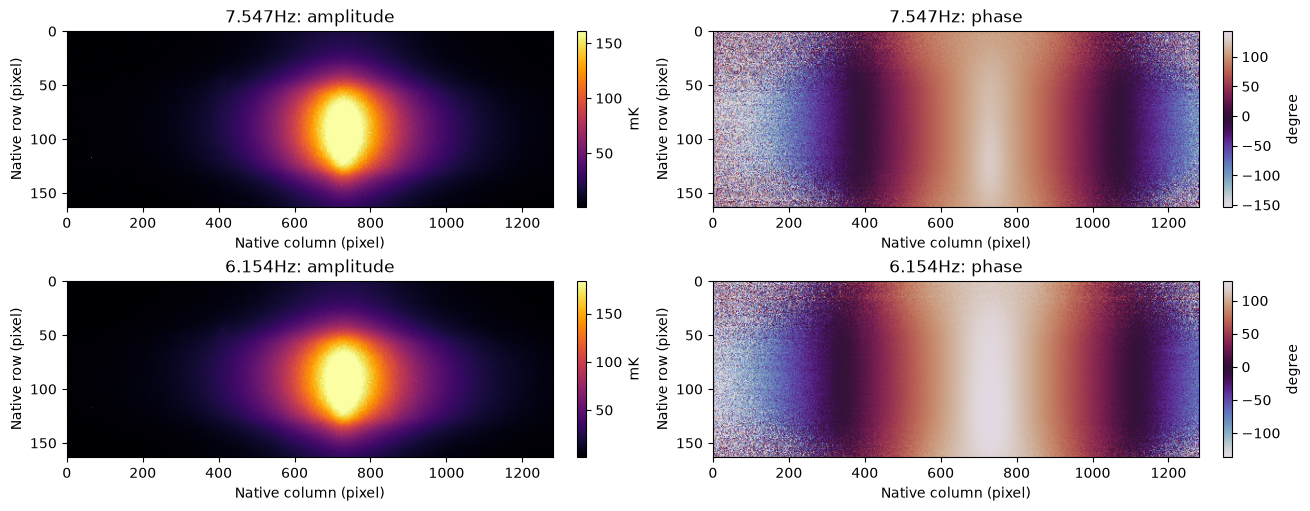

In [2]:
fig,axes=plt.subplots(2,2,figsize=(13,5),layout='constrained')
for i in range(2):
    for j,data in enumerate((amplitude,phase)):
        im=axes[i,j].imshow(data[i],aspect='auto',cmap=['inferno','twilight'][j],vmin=np.percentile(data[i],2),vmax=np.percentile(data[i],98))
        axes[i,j].set(title=f'{FREQUENCIES[i]}Hz: '+['amplitude','phase'][j],xlabel='Native column (pixel)',ylabel='Native row (pixel)')
        fig.colorbar(im,ax=axes[i,j],label=['mK','degree'][j])
plt.show()

# Physics
On each outward branch, $\partial_t T=\alpha\partial_z^2T-hT$, where $\alpha$ is diffusivity in mm²/s and $h$ is a heat-loss rate in s⁻¹. A harmonic temperature $U=C\exp[-(a+ib)z]$ has $(a+ib)^2=(h+i2\pi f)/\alpha$. Thus the log-amplitude and phase slopes are $m_A=-a$ and $m_P=-b$, and $\alpha=\pi f/(m_A m_P)$. The product cancels linear loss. In contrast, the lossless formulas $\pi f/m_A^2$ and $\pi f/m_P^2$ can disagree. Source amplitude and a constant phase offset affect intercepts, not diffusivity. The approximation excludes the laser spot and specimen endpoints.

# Method
The local implementation follows the author pipeline: degree conversion, native90° orientation, observed bright-ridge alignment, source localization, central-column branches and linear fits on0.2–0.6mm. It uses explicit ordinary least squares and slope products. The joint estimator fits products versus frequency through the origin. There is no training or hidden target calibration. Complete reconstruction is active below.

Fresh full reconstruction seconds: 0.029027199954725802
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "relative_error": 1.1228462604151446e-11,
    "coefficient_relative_error": 7.771561172376096e-16,
    "log_amplitude_rmse": 0.0790168099905262,
    "phase_rmse": 0.07679799642444958
  },
  "thresholds": {
    "relative_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "coefficient_relative_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "log_amplitude_rmse": {
      "comparison": "<=",
      "boundary": 0.08691849098957881
    },
    "phase_rmse": {
      "comparison": "<=",
      "boundary": 0.08447779606689454
    }
  },
  "errors": []
}
reconstruction max relative difference from reproduced original: 8.881784197001252e-16
fit_parameters max relative difference from reproduced original: 7.771561172376096e-16
joint_diffusivity max relative difference from reproduced original: 1.1228462604151446e-11


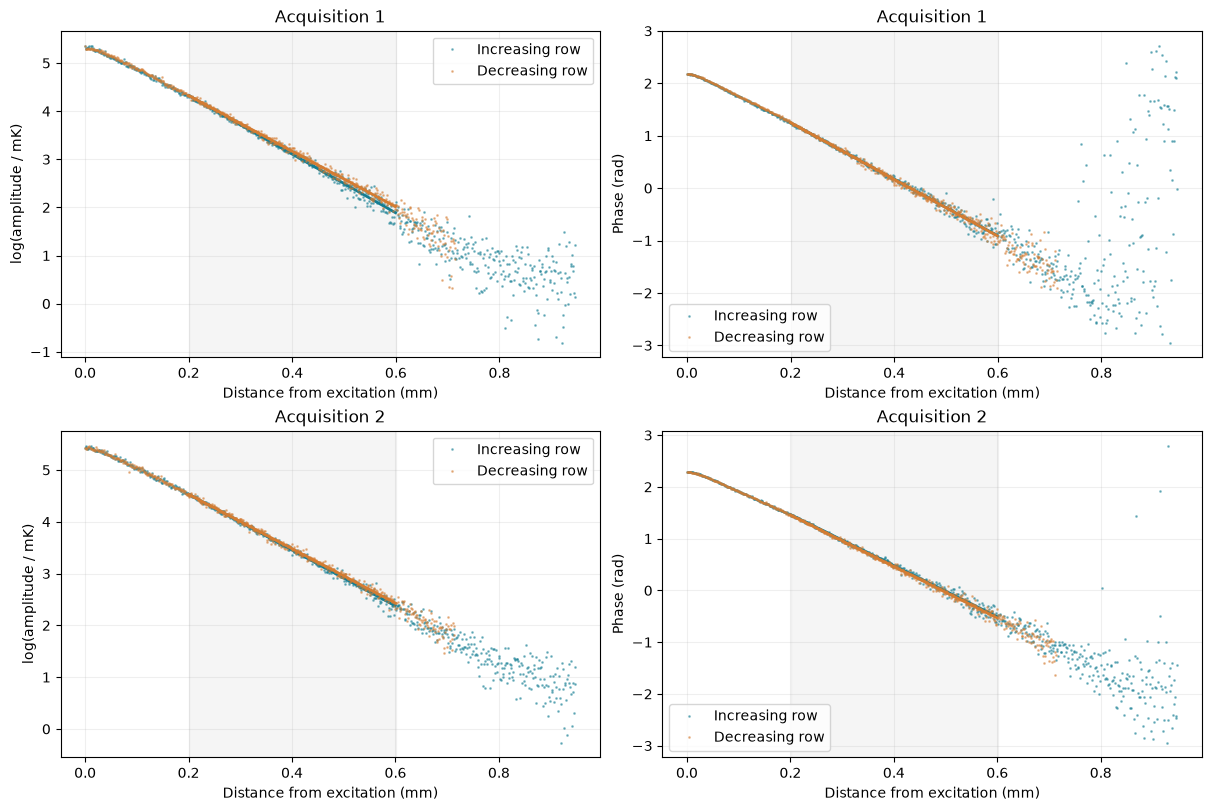

In [3]:
start=time.perf_counter()
fresh,rows=reconstruct(amplitude,phase)
runtime=time.perf_counter()-start
prediction=ROOT/'output/reconstruction.npz';np.savez_compressed(prediction,**fresh)
report=judge.evaluate(prediction)
print('Fresh full reconstruction seconds:',runtime)
print(json.dumps(report,indent=2))
assert report['passed']
for key in fresh:print(key,'max relative difference from reproduced original:',relative_error(fresh[key],upstream[key]))
profile_figure(rows);plt.show()

# Results
The full profiles show why the source neighborhood and noisy far field are excluded. Fits use both sides independently. The following comparisons are freshly evaluated: lossless amplitude-only and phase-only estimators, the selected product method, a joint frequency estimate, two alternative windows, and an orientation ablation. The original reference is labeled separately.

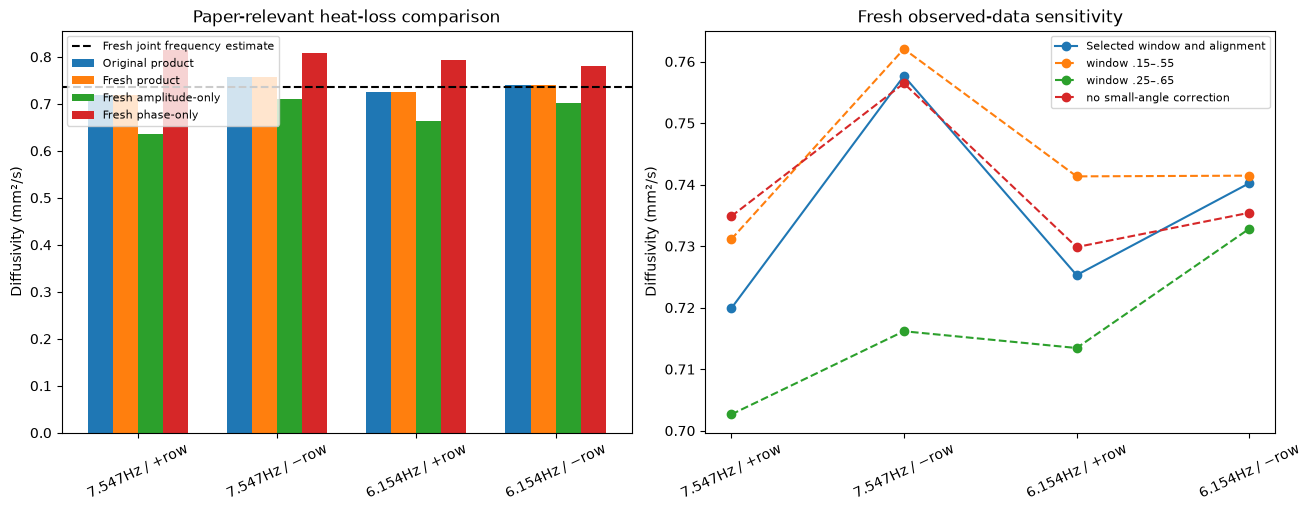

Fresh product diffusivity: [[[0.71986158 0.75765242]
  [0.7252879  0.74023614]]]
Fresh joint diffusivity: [[0.73603187]]
Window/alignment comparisons: {'window .15–.55': [[[0.7311021548853508, 0.7620501331849173], [0.7413374261480603, 0.7414542185018096]]], 'window .25–.65': [[[0.70263513909349, 0.7161651247937648], [0.7134391312074245, 0.7328354769049699]]], 'no small-angle correction': [[[0.7348322176398553, 0.7564578140620432], [0.7298451093998001, 0.7354253210440791]]]}


In [4]:
c=fresh['fit_parameters'][0]
amplitude_only=np.pi*FREQUENCIES[:,None]/c[:,:,0,0]**2
phase_only=np.pi*FREQUENCIES[:,None]/c[:,:,1,0]**2
variants={}
for name,kwargs in [('window .15–.55',dict(fit_window=(.15,.55))),('window .25–.65',dict(fit_window=(.25,.65))),('no small-angle correction',dict(correct_angle=False))]:
    variants[name]=reconstruct(amplitude,phase,**kwargs)[0]
labels=[f'{f}Hz / {s}' for f in FREQUENCIES for s in ['+row','−row']]
x=np.arange(4);fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for off,(name,v) in zip([-.27,-.09,.09,.27],[('Original product',upstream['reconstruction'][0]),('Fresh product',fresh['reconstruction'][0]),('Fresh amplitude-only',amplitude_only),('Fresh phase-only',phase_only)]):
    axes[0].bar(x+off,v.ravel(),.18,label=name)
axes[0].axhline(fresh['joint_diffusivity'][0,0],color='black',ls='--',label='Fresh joint frequency estimate')
axes[0].set(xticks=x,xticklabels=labels,ylabel='Diffusivity (mm²/s)',title='Paper-relevant heat-loss comparison');axes[0].tick_params(axis='x',rotation=25);axes[0].legend(fontsize=8)
axes[1].plot(x,fresh['reconstruction'].ravel(),'o-',label='Selected window and alignment')
for name,v in variants.items():axes[1].plot(x,v['reconstruction'].ravel(),'o--',label=name)
axes[1].set(xticks=x,xticklabels=labels,ylabel='Diffusivity (mm²/s)',title='Fresh observed-data sensitivity');axes[1].tick_params(axis='x',rotation=25);axes[1].legend(fontsize=8)
plt.show()
print('Fresh product diffusivity:',fresh['reconstruction'])
print('Fresh joint diffusivity:',fresh['joint_diffusivity'])
print('Window/alignment comparisons:',{k:v['reconstruction'].tolist() for k,v in variants.items()})

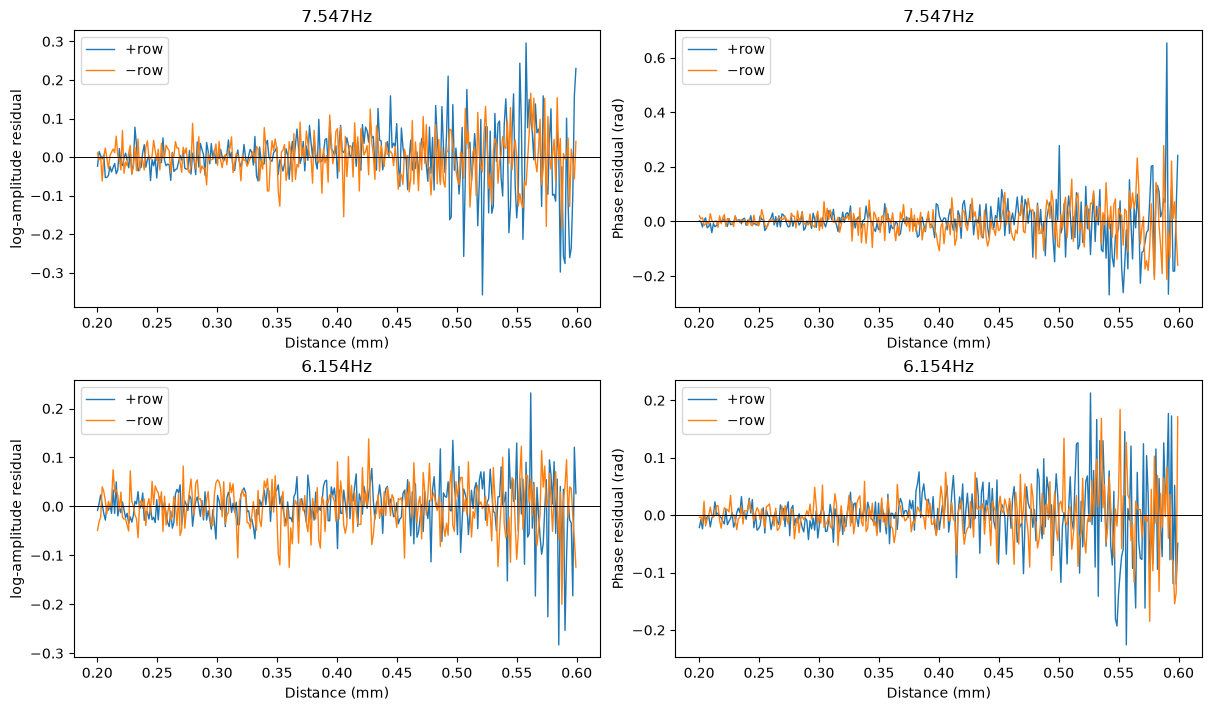

RMS residuals [frequency, branch, log-amplitude/phase]: [[[0.07901681 0.076798  ]
  [0.05476737 0.06056911]]

 [[0.05158652 0.0548808 ]
  [0.04627194 0.04145506]]]


In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,7),layout='constrained')
residuals=[]
for i,r in enumerate(rows):
    lo,hi=r['fit_indices'];d=r['distance'][lo:hi]
    res=np.empty((2,len(d),2))
    for s in range(2):
        for m in range(2):
            res[s,:,m]=r['profiles'][s,lo:hi,m]-np.polyval(r['coefficients'][s,m],d)
            axes[i,m].plot(d,res[s,:,m],label=['+row','−row'][s],lw=1)
    residuals.append(np.sqrt(np.mean(res**2,axis=1)))
    for m in range(2):axes[i,m].axhline(0,color='black',lw=.7);axes[i,m].set(xlabel='Distance (mm)',ylabel=['log-amplitude residual','Phase residual (rad)'][m],title=f'{FREQUENCIES[i]}Hz');axes[i,m].legend()
plt.show()
print('RMS residuals [frequency, branch, log-amplitude/phase]:',np.array(residuals))

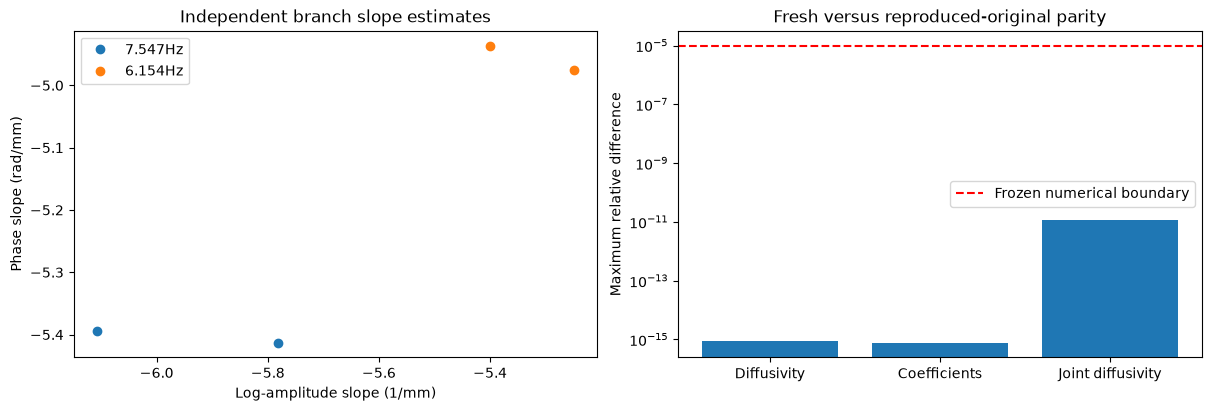

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for i,r in enumerate(rows):
    axes[0].plot(r['coefficients'][:,0,0],r['coefficients'][:,1,0],'o',label=f'{FREQUENCIES[i]}Hz')
axes[0].set(xlabel='Log-amplitude slope (1/mm)',ylabel='Phase slope (rad/mm)',title='Independent branch slope estimates');axes[0].legend()
names=['Diffusivity','Coefficients','Joint diffusivity'];keys=['reconstruction','fit_parameters','joint_diffusivity']
values=[relative_error(fresh[k],upstream[k]) for k in keys]
axes[1].bar(names,values);axes[1].set(yscale='log',ylabel='Maximum relative difference',title='Fresh versus reproduced-original parity')
axes[1].axhline(1e-5,ls='--',color='red',label='Frozen numerical boundary');axes[1].legend()
plt.show()
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_measurements.npz',**fresh,runtime_seconds=np.array([runtime]),residual_rms=np.array(residuals)[None])

# Conclusion
The complete local reconstruction agrees with the reproduced original and satisfies independently frozen observation residual limits. Heat-loss-sensitive estimators and window choices produce measurable differences on these same real observations. Residual structure and branch disagreement remain visible; method parity cannot establish absolute material accuracy. Only two frequencies are available, so this notebook does not claim a complete plateau, power sweep, independent truth, or the paper's stated physical uncertainty for QF01.